In [1]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path

import pandas as pd
from matplotlib import pyplot as plt

from notebooks.imports import *
from src.utils import pmf_utils

### Config

In [3]:
from config import dir_config

raw_dir = Path(dir_config.data.raw)
processed_dir = Path(dir_config.data.processed)

### Utils functions

In [4]:
def plot_psych(x, y, x_hat, y_hat) -> None:
	fig, ax = plt.subplots()
	ax.plot(x, y, "o", label="Original Data")
	ax.plot(x_hat, y_hat, "r-", label="Fitted Curve")
	ax.set_xlabel("Coherence")
	ax.set_ylabel("Probability of Correct Response")
	ax.set_xlim(-100, 100)
	ax.set_ylim(0, 1)
	ax.legend()
	plt.show()


def plot_pulse_psych(psych_curves, ms=10, lw=3, alpha=1, suptitle="", fig=None, ax=None, legend=True):
	if (ax is None) or (fig is None):
		fig, ax = plt.subplots(1, 3, figsize=(18, 6))

	# early pulse
	if 1 in psych_curves:
		ax[0].plot(psych_curves[0]["x"], psych_curves[0]["y"], "ko", ms=ms, alpha=alpha)
		ax[0].plot(psych_curves[0]["x_hat"], psych_curves[0]["y_hat"], "k-", lw=lw, alpha=alpha, label="Control")
		ax[0].plot(psych_curves[1]["x"], psych_curves[1]["y"], "bo", ms=ms, alpha=alpha)
		ax[0].plot(psych_curves[1]["x_hat"], psych_curves[1]["y_hat"], "b-", lw=lw, alpha=alpha, label="Early Positive")
		ax[0].plot(psych_curves[-1]["x"], psych_curves[-1]["y"], "ro", ms=ms, alpha=alpha)
		ax[0].plot(psych_curves[-1]["x_hat"], psych_curves[-1]["y_hat"], "r-", lw=lw, alpha=alpha, label="Early Negative")
		ax[0].set_xlabel("Coherence")
		ax[0].set_ylabel("Probability of Positive Response", fontsize=16)
		ax[0].legend() if legend else None
		ax[0].set_title("Early Pulse", fontsize=22)
		ax[0].set_xlim(-105, 105)
		ax[0].set_ylim(-0.05, 1.05)
		ax[0].set_xticks([-100, -35, -13, 0, 13, 35, 100])
		ax[0].tick_params(axis="both", labelsize=16)
		ax[0].spines["top"].set_visible(False)
		ax[0].spines["right"].set_visible(False)
		ax[0].grid(False)

	# mid pulse
	if 2 in psych_curves:
		ax[1].plot(psych_curves[0]["x"], psych_curves[0]["y"], "ko", ms=ms, alpha=alpha)
		ax[1].plot(psych_curves[0]["x_hat"], psych_curves[0]["y_hat"], "k-", lw=lw, alpha=alpha, label="Control")
		ax[1].plot(psych_curves[2]["x"], psych_curves[2]["y"], "bo", ms=ms, alpha=alpha)
		ax[1].plot(psych_curves[2]["x_hat"], psych_curves[2]["y_hat"], "b-", lw=lw, alpha=alpha, label="Mid Positive")
		ax[1].plot(psych_curves[-2]["x"], psych_curves[-2]["y"], "ro", ms=ms, alpha=alpha)
		ax[1].plot(psych_curves[-2]["x_hat"], psych_curves[-2]["y_hat"], "r-", lw=lw, alpha=alpha, label="Mid Negative")
		ax[1].set_xlabel("Coherence")
		ax[1].set_ylabel("Probability of Positive Response", fontsize=16)
		ax[1].set_ylim(0, 1)
		ax[1].legend() if legend else None
		ax[1].set_title("Mid Pulse", fontsize=22)
		ax[1].set_xlim(-105, 105)
		ax[1].set_ylim(-0.05, 1.05)
		ax[1].set_xticks([-100, -35, -13, 0, 13, 35, 100])
		ax[1].tick_params(axis="both", labelsize=16)
		ax[1].spines["top"].set_visible(False)
		ax[1].spines["right"].set_visible(False)
		ax[1].grid(False)

	# late pulse
	if 3 in psych_curves:
		ax[2].plot(psych_curves[0]["x"], psych_curves[0]["y"], "ko", ms=ms, alpha=alpha)
		ax[2].plot(psych_curves[0]["x_hat"], psych_curves[0]["y_hat"], "k-", lw=lw, alpha=alpha, label="Control")
		ax[2].plot(psych_curves[3]["x"], psych_curves[3]["y"], "bo", ms=ms, alpha=alpha)
		ax[2].plot(psych_curves[3]["x_hat"], psych_curves[3]["y_hat"], "b-", lw=lw, alpha=alpha, label="late Positive")
		ax[2].plot(psych_curves[-3]["x"], psych_curves[-3]["y"], "ro", ms=ms, alpha=alpha)
		ax[2].plot(psych_curves[-3]["x_hat"], psych_curves[-3]["y_hat"], "r-", lw=lw, alpha=alpha, label="late Negative")
		ax[2].set_xlabel("Coherence")
		ax[2].set_ylabel("Probability of Positive Response", fontsize=16)
		ax[2].set_ylim(0, 1)
		ax[2].legend() if legend else None
		ax[2].set_title("Late Pulse", fontsize=22)
		ax[2].set_xlim(-105, 105)
		ax[2].set_ylim(-0.05, 1.05)
		ax[2].set_xticks([-100, -35, -13, 0, 13, 35, 100])
		ax[2].tick_params(axis="both", labelsize=16)
		ax[2].spines["top"].set_visible(False)
		ax[2].spines["right"].set_visible(False)
		ax[2].grid(False)

	if suptitle:
		fig.suptitle(suptitle)

	return fig, ax

#### Pulse types
- -3: 'late_negative_pulse'
- -2: 'middle_negative_pulse'
- -1: 'early_negative_pulse'
- 0: 'control'
- 1: 'early_positive_pulse'
- 2: 'middle_positive_pulse'
- 3: 'late_positive_pulse'


### Load data

In [5]:
data = pd.read_csv(Path(processed_dir, "valid_data.csv"), index_col=None)

data = data[data["subject_id"] != "DBM6"]

data

,idx_session,data_source,subject_id,session_id,idx_valid_trial,idx_correction,is_correction_trial,signed_coherence,target,choice,reaction_time,outcome,reward_amount,fixation_duration,stimulus_duration,reinforcement_duration,intertrial_delay,is_pulse_trial,pulse_onset,pulse_duration,pulse_coherence,stimulus_seed,pulse_type
0,0,uw,DBM11,10_1,1,0,False,100,1,1,1.080817,1.0,1.5,0.530901,25.0,0.0,0.500000,True,0.416750,0.066680,-100,612658,-3.0
1,0,uw,DBM11,10_1,2,0,False,100,1,0,0.469520,0.0,NaN,0.577326,25.0,0.0,13.689771,False,0.416750,0.066680,100,463182,0.0
2,0,uw,DBM11,10_1,3,0,False,-100,-1,0,2.171707,1.0,1.5,0.556890,25.0,0.0,0.500000,True,0.416750,0.066680,100,165712,3.0
3,0,uw,DBM11,10_1,4,0,False,-100,-1,0,0.476003,1.0,1.5,0.548262,25.0,0.0,0.500000,False,0.050010,0.066680,-100,418800,-0.0
4,0,uw,DBM11,10_1,5,0,False,-100,-1,0,0.971870,1.0,1.5,0.561377,25.0,0.0,0.500000,False,0.233380,0.066680,-100,372882,-0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113869,297,ucla,PSUIM9,9_1,346,0,False,18,1,1,1.108688,1.0,2.6,1.000000,60.0,0.5,0.250000,True,0.029568,0.050560,100,346,1.0
113870,297,ucla,PSUIM9,9_1,347,0,False,36,1,1,1.598707,1.0,2.6,1.000000,60.0,0.5,0.250000,False,NaN,NaN,0,347,0.0
113871,297,ucla,PSUIM9,9_1,348,0,False,-9,-1,1,2.292042,0.0,0.0,1.000000,60.0,1.5,0.252608,False,NaN,NaN,0,348,0.0
113872,297,ucla,PSUIM9,9_1,349,0,False,36,1,1,1.706793,1.0,2.6,1.000000,60.0,0.5,0.250000,True,0.240538,0.050291,100,349,2.0


In [6]:
subject_sessions = data.groupby("subject_id")["session_id"].nunique().reset_index(name="count")
subject_sessions

,subject_id,count
0,DBM11,15
1,DBM12,17
2,DBM13,5
3,DBM14,16
4,DBM15,33
5,DBM16,9
6,DBM5,23
7,DBM8,13
8,PSUIM10,8
9,PSUIM5,10


### Plot psychometric functions

In [9]:
data.pulse_type.unique()


array([-3.,  0.,  3., -2.,  2., -1.,  1.])

In [7]:
# run utils.get_psychometric_curve function for each subset of pulse_type
psych_curves = {}

for pulse_type in data.pulse_type.unique():
	x, y, model, x_hat, y_hat = pmf_utils.get_psychometric_data(data[data.pulse_type == pulse_type])

	psych_curves[pulse_type] = {
		"x": x,
		"y": y,
		"model": model,
		"x_hat": x_hat,
		"y_hat": y_hat,
	}

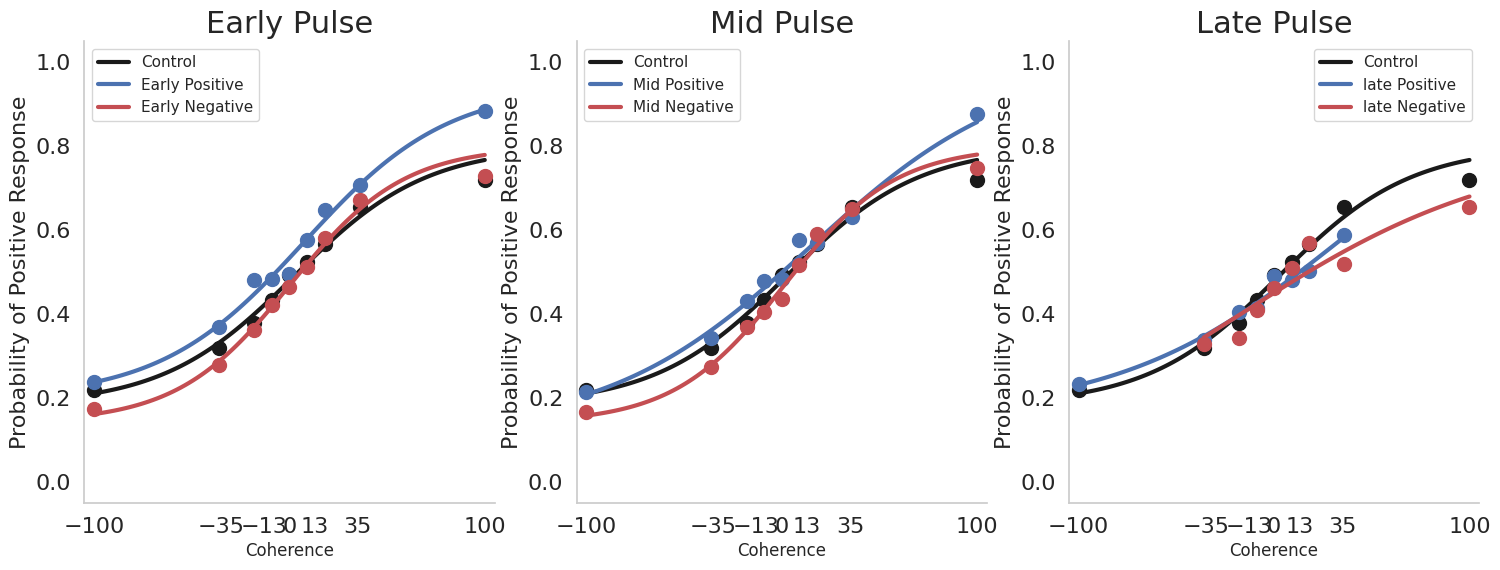

In [ ]:
plot_pulse_psych(psych_curves)

# Calculating choice bias based on GLM including pulse information

Kiani et al 2008
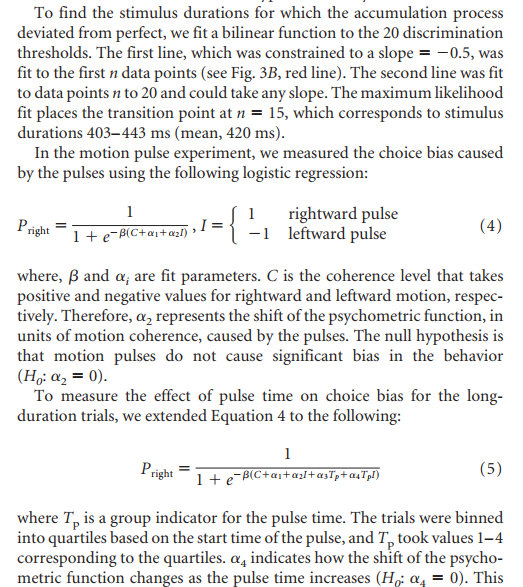

In [42]:
import numpy as np
from scipy.optimize import curve_fit


# Define the model functions
def pulse_glm_fit(x, beta, lapse, alpha_1, alpha_2):
	coh, pulse_dir = x  # Unpack tuple input
	expon_eq = -beta * (coh + alpha_1) + (pulse_dir * alpha_2)
	return lapse + ((1 - 2 * lapse) / (1 + np.exp(expon_eq)))


def pulse_time_glm_fit(x, beta, lapse, alpha_1, alpha_2, alpha_3, alpha_4):
	coh, pulse_dir, pulse_time = x  # Unpack tuple input
	expon_eq = -beta * (coh + alpha_1 + (pulse_dir * alpha_2) + (alpha_3 * pulse_time) + (alpha_4 * (pulse_dir * pulse_time)))
	return lapse + (1 - 2 * lapse) / (1 + np.exp(expon_eq))


def fit(model, x, y):
	# Parameter bounds
	beta = (1e-5, 30)
	lapse = (0, 0.3)
	alpha_1 = (-1, 1)
	alpha_2 = (-1, 1)
	alpha_3 = (-1, 1)
	alpha_4 = (-1, 1)

	param_lims = [beta, lapse, alpha_1]
	if model == "pulse":
		_fit_func = pulse_glm_fit
		param_lims.append(alpha_2)
	elif model == "pulse_time":
		_fit_func = pulse_time_glm_fit
		param_lims.extend([alpha_2, alpha_3, alpha_4])

	# Prepare bounds and initial guess
	bounds = list(zip(*param_lims))
	initial_guess = [np.mean(b) for b in param_lims]  # Use the mean of bounds as initial guess

	sigma = None

	# Fit using curve_fit
	popt, pcov = curve_fit(_fit_func, x, y, p0=initial_guess, bounds=bounds, sigma=sigma, absolute_sigma=False)

	# Print results
	print("Optimized Parameters:", popt)

	return popt, pcov


def get_alpha(pulse_type, model, fit_params):
	pulse_dir = np.sign(pulse_type)
	pulse_time = np.abs(pulse_type)
	if model == "pulse":
		alpha = pulse_dir * fit_params[3]
	elif model == "pulse_time":
		alpha = (pulse_dir * fit_params[3]) + (fit_params[4] * pulse_time) + (fit_params[5] * (pulse_dir * pulse_time))
	return alpha

#### Pulse types
- -3: 'late_negative_pulse'
- -2: 'middle_negative_pulse'
- -1: 'early_negative_pulse'
- 0: 'control'
- 1: 'early_positive_pulse'
- 2: 'middle_positive_pulse'
- 3: 'late_positive_pulse'

In [43]:
# Preprocess DataFrame
pulse_dir = data.pulse_type.map({1: 1, 2: 1, 3: 1, 0: 0, -1: -1, -2: -1, -3: -1}).values
pulse_time = np.abs(data.pulse_type.values)
coh = data.signed_coherence.values / 100
y = data.choice.values.astype(float)  # Ensure `choice` is numerical

# Select model and format `x` correctly
model = "pulse_time"

if model == "pulse":
	x = (coh, pulse_dir)
elif model == "pulse_time":
	x = (coh, pulse_dir, pulse_time)

# Fit model
fit_params, fit_cov = fit(model, x, y)
if model == "pulse":
	y_hat = pulse_glm_fit(x, *fit_params)
elif model == "pulse_time":
	y_hat = pulse_time_glm_fit(x, *fit_params)


alpha_1 = fit_params[2]
alpha_2 = fit_params[3]
alpha_3 = fit_params[4]
alpha_4 = fit_params[5]

Optimized Parameters: [ 3.68166219  0.22660907 -0.02967574  0.12052326 -0.01102792 -0.04113757]


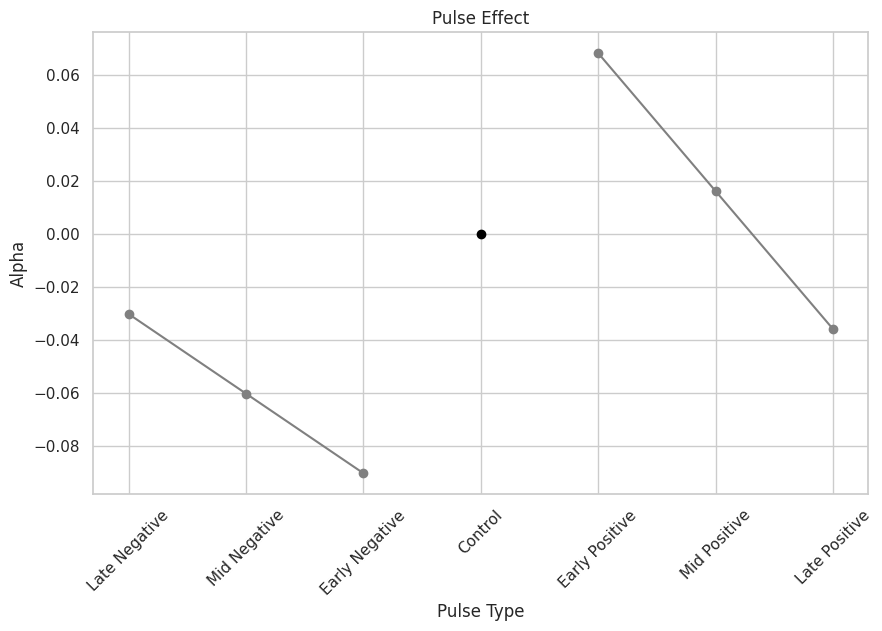

In [44]:
plt.figure(figsize=(10, 6))
pulses = [-3, -2, -1]
plt.plot(pulses, [get_alpha(p, model, fit_params) for p in pulses], "o-", color="gray")
pulses = [1, 2, 3]
plt.plot(pulses, [get_alpha(p, model, fit_params) for p in pulses], "o-", color="gray")
pulses = [0]
plt.plot(pulses, [get_alpha(p, model, fit_params) for p in pulses], "o-", color="black")

plt.xticks([-3, -2, -1, 0, 1, 2, 3], ["Late Negative", "Mid Negative", "Early Negative", "Control", "Early Positive", "Mid Positive", "Late Positive"], rotation=45)
plt.title("Pulse Effect")
plt.xlabel("Pulse Type")
plt.ylabel("Alpha");

# Fit Individual Sesssions and compare relative alpha change ()


📌 GLM Results for Pulse Model:

                 Generalized Linear Model Regression Results                  
Dep. Variable:                 choice   No. Observations:                99599
Model:                            GLM   Df Residuals:                    99596
Model Family:                Binomial   Df Model:                            2
Link Function:                  logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -64412.
Date:                Sat, 08 Mar 2025   Deviance:                   1.2882e+05
Time:                        03:19:36   Pearson chi2:                 9.99e+04
No. Iterations:                     5   Pseudo R-squ. (CS):            0.08734
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.08

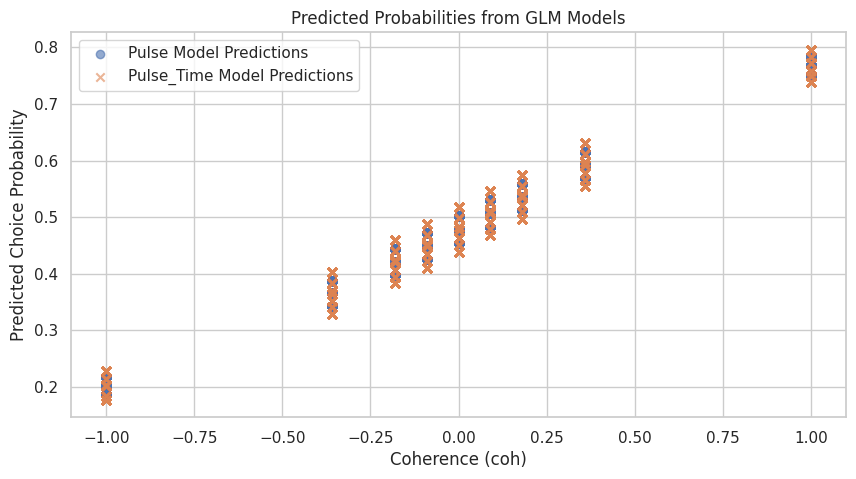

In [46]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.genmod.families import Binomial
from statsmodels.genmod.families.links import logit

# Set random seed for reproducibility
np.random.seed(42)

# Generate synthetic data similar to motion energy experiments
glm_data = pd.DataFrame(
	{
		"coh": data.signed_coherence / 100,  # Signed coherence (motion strength)
		"pulse_dir": data.pulse_type.map({1: 1, 2: 1, 3: 1, 0: 0, -1: -1, -2: -1, -3: -1}),  # Direction of the pulse
		"pulse_time": np.abs(data.pulse_type),  # Time of the pulse event
		"choice": data.choice.astype(float),  # Binary response (0 or 1)
	}
)

### **1️⃣ Fit GLM for Pulse Model (without pulse_time)**
formula_pulse = "choice ~ coh + pulse_dir"
glm_pulse = smf.glm(formula=formula_pulse, data=glm_data, family=Binomial(link=logit())).fit()

print("\n📌 GLM Results for Pulse Model:\n")
print(glm_pulse.summary())

### **2️⃣ Fit GLM for Pulse_Time Model (including pulse_time interaction)**
formula_pulse_time = "choice ~ coh + pulse_dir + pulse_time + pulse_dir:pulse_time"
glm_pulse_time = smf.glm(formula=formula_pulse_time, data=glm_data, family=Binomial(link=logit())).fit()

print("\n📌 GLM Results for Pulse_Time Model:\n")
print(glm_pulse_time.summary())

### **3️⃣ Model Comparison using AIC (lower is better)**
print("\n✅ Model Comparison (Lower AIC is better):")
print(f"AIC for Pulse Model: {glm_pulse.aic}")
print(f"AIC for Pulse_Time Model: {glm_pulse_time.aic}")

### **4️⃣ Predict probabilities using the fitted model**
glm_data["predicted_choice_pulse"] = glm_pulse.predict(glm_data)
glm_data["predicted_choice_pulse_time"] = glm_pulse_time.predict(glm_data)


### **5️⃣ Plot Model Predictions**
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.scatter(glm_data["coh"], glm_data["predicted_choice_pulse"], label="Pulse Model Predictions", alpha=0.6)
plt.scatter(glm_data["coh"], glm_data["predicted_choice_pulse_time"], label="Pulse_Time Model Predictions", alpha=0.6, marker="x")
plt.xlabel("Coherence (coh)")
plt.ylabel("Predicted Choice Probability")
plt.legend()
plt.title("Predicted Probabilities from GLM Models")
plt.show()

# TEST